In [1]:
PATH = "Assignment2 Data/"

In [2]:
!pip install scikit-image

Defaulting to user installation because normal site-packages is not writeable


## 1. Image Classification using HoG

In [3]:
TRAIN_DIR = PATH+"Q1/training"
TEST_DIR = PATH+"Q1/test"

In [4]:
from skimage.io import imread
from skimage.transform import resize
from skimage.feature import hog
from sklearn.neighbors import KNeighborsClassifier
import matplotlib.pyplot as plt
import cv2
import os 
import numpy as np

### 1.1 Build a classifier with training images

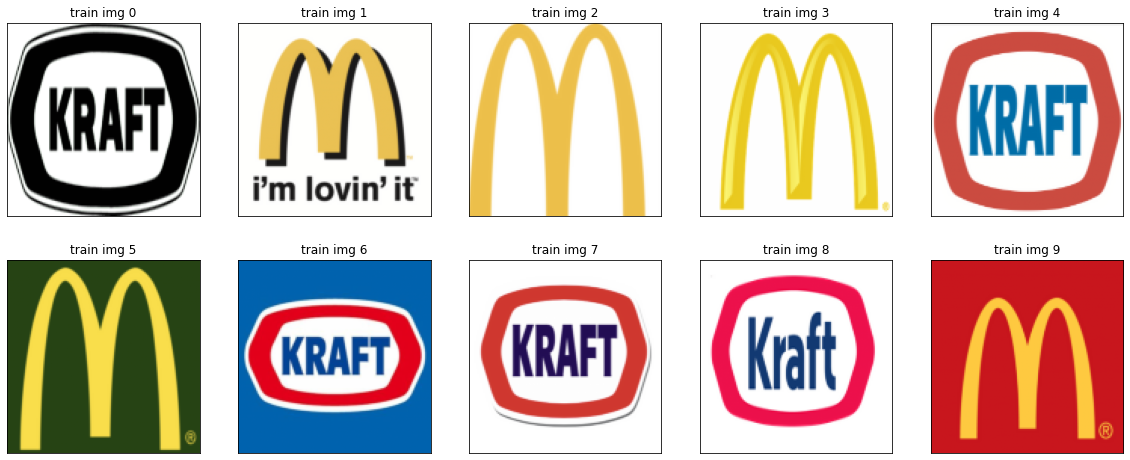

In [5]:
# 1. Resize the training images to 128 x 128. 
# read, resize, and show training set images 

IMG_SIZE = (128, 128) 
TRAIN_IMAGES = [] 
TEST_IMAGES = []
fig, ax = plt.subplots(2, 5, figsize=(20, 8))


# read images in the train and test directory 
counter = 0
for image_f in os.listdir(TRAIN_DIR):
    img = imread(os.path.join(TRAIN_DIR, image_f)) # resize train images
    img = resize(img, IMG_SIZE)
    TRAIN_IMAGES.append(img)
    ax[counter//5][counter%5].imshow(img)
    ax[counter//5][counter%5].title.set_text(f"train img {counter}")
    ax[counter//5][counter%5].tick_params(left=False, right=False, labelleft=False, labelbottom=False, bottom=False)
    counter += 1

/tmp/ipykernel_1752527/955082359.py:8: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  hog_features = np.asarray([hog(img, orientations=NUM_ORIENTATION_BINS, pixels_per_cell=PIXELS_CELL,cells_per_block=CELLS_BLOCK, visualize=True, channel_axis=-1) for img in TRAIN_IMAGES])


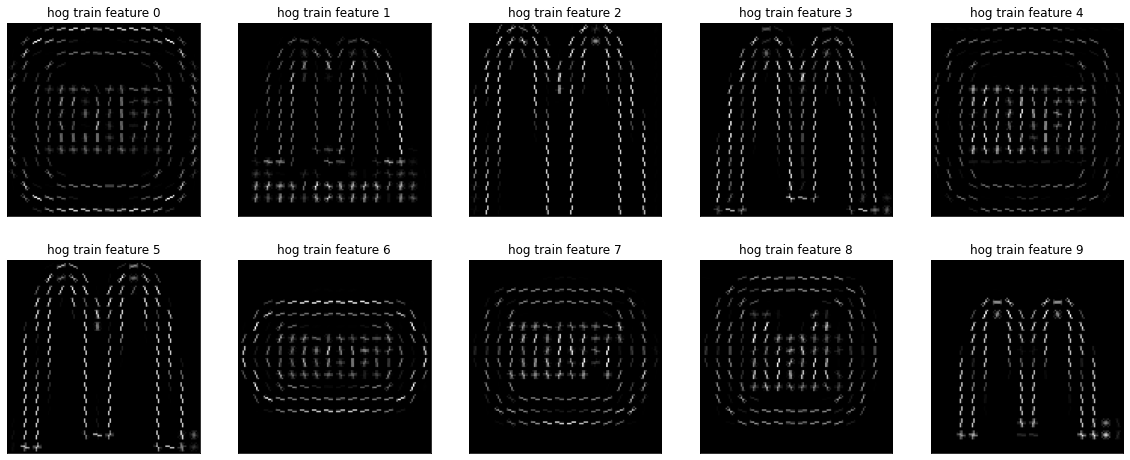

In [6]:
# constants 
PIXELS_CELL = (8, 8)
CELLS_BLOCK = (4, 4)
NUM_ORIENTATION_BINS = 8

# 2. Compute HoG features of size (32, 32, 8) for all training images.
# 3. Apply blocknorm in 4x4 cell neighborhoods.
hog_features = np.asarray([hog(img, orientations=NUM_ORIENTATION_BINS, pixels_per_cell=PIXELS_CELL,cells_per_block=CELLS_BLOCK, visualize=True, channel_axis=-1) for img in TRAIN_IMAGES])



counter = 0
fig, ax = plt.subplots(2, 5, figsize=(20, 8))
for features in hog_features:
    ax[counter//5][counter%5].imshow(features[1], cmap="gray")
    ax[counter//5][counter%5].title.set_text(f"hog train feature {counter}")
    ax[counter//5][counter%5].tick_params(left=False, right=False, labelleft=False, labelbottom=False, bottom=False)
    counter += 1
    

features = np.array([features[0] for features in hog_features])

In [7]:
# manually label train images 
targets = ["Kraft", "McDonald’s", "McDonald’s", "McDonald’s", "Kraft", "McDonald’s", "Kraft", "Kraft", "Kraft", "McDonald’s"]

# 4. Fit a nearest neighbor classifier with three neighbors. Use KNeighborsClassifier from sklearn library.
N_NEIGHBORS = 3
clf = KNeighborsClassifier(n_neighbors = N_NEIGHBORS)
clf.fit(features, targets)

KNeighborsClassifier(n_neighbors=3)

### 1.2 Classify test images

/tmp/ipykernel_1752527/798959587.py:15: VisibleDeprecationWarning: Creating an ndarray from ragged nested sequences (which is a list-or-tuple of lists-or-tuples-or ndarrays with different lengths or shapes) is deprecated. If you meant to do this, you must specify 'dtype=object' when creating the ndarray.
  hog_test_features = np.asarray([hog(img, orientations=NUM_ORIENTATION_BINS, pixels_per_cell=PIXELS_CELL,cells_per_block=CELLS_BLOCK, visualize=True, channel_axis=-1) for img in TEST_IMAGES])


Predicted Label: ['Kraft' 'Kraft' 'Kraft' 'McDonald’s']


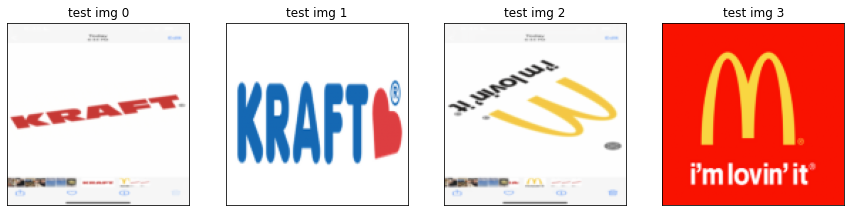

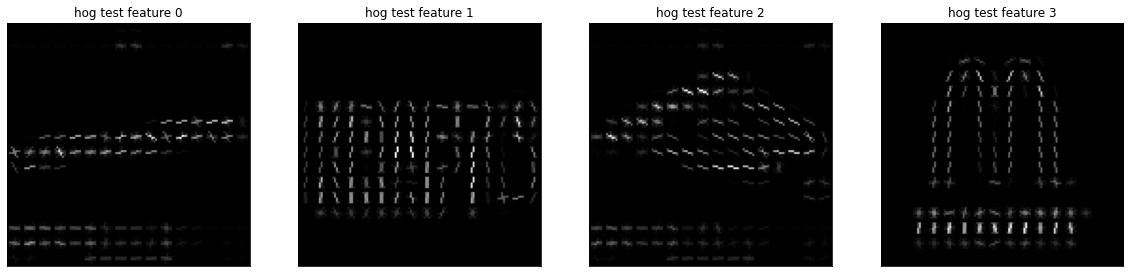

In [8]:
#1. Compute HoG features for all test images.

fig, ax = plt.subplots(1, 4, figsize=(15, 5))
counter = 0
for image_f in os.listdir(TEST_DIR):
    img = imread(os.path.join(TEST_DIR, image_f)) # resize train images
    img = resize(img, IMG_SIZE)
    TEST_IMAGES.append(img)
    ax[counter%4].imshow(img)
    ax[counter%4].title.set_text(f"test img {counter}")
    ax[counter%4].tick_params(left=False, right=False, labelleft=False, labelbottom=False, bottom=False)
    counter += 1
    
#2. Display the HoG features for all test images.
hog_test_features = np.asarray([hog(img, orientations=NUM_ORIENTATION_BINS, pixels_per_cell=PIXELS_CELL,cells_per_block=CELLS_BLOCK, visualize=True, channel_axis=-1) for img in TEST_IMAGES])
counter = 0
fig, ax = plt.subplots(1, 4, figsize=(20, 8))
for features in hog_test_features:
    ax[counter%4].imshow(features[1], cmap="gray")
    ax[counter%4].title.set_text(f"hog test feature {counter}")
    ax[counter%4].tick_params(left=False, right=False, labelleft=False, labelbottom=False, bottom=False)
    counter += 1
    
features_test = np.array([features[0] for features in hog_test_features])

# 3. Classify the test images using the classifier you built above.
# predict test set labels 
print("Predicted Label:", clf.predict(features_test))

4. Does the classifier work on all test images? Discuss which properties of HoG features help
to classify the images. Which computer vision methods will you use for classifying logos
under rotation.

Answer here

## 2. Image stitching 

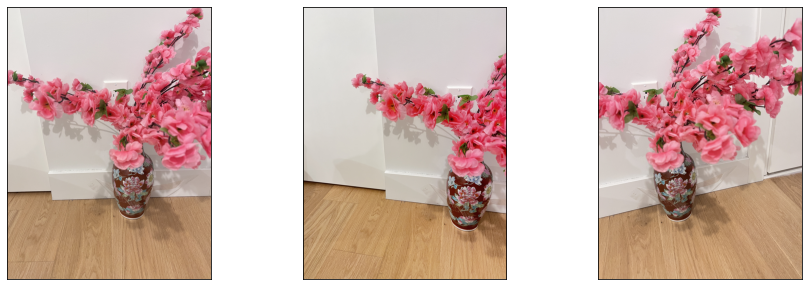

In [36]:
img1 = cv2.imread(PATH + "Q2/image2.jpeg")  # in BGR
img2 = cv2.imread(PATH + "Q2/image1.jpeg")  # in BGR
img3 = cv2.imread(PATH + "Q2/image3.jpeg")  # in BGR

img1 = cv2.cvtColor(img1, cv2.COLOR_BGR2RGB)
img2 = cv2.cvtColor(img2, cv2.COLOR_BGR2RGB)
img3 = cv2.cvtColor(img3, cv2.COLOR_BGR2RGB)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(img1)
ax[1].imshow(img2)
ax[2].imshow(img3)
for axs in ax: 
    axs.tick_params(left=False, right=False, labelleft=False, labelbottom=False, bottom=False)

In [37]:
#1. Compute the SIFT keypoints and corresponding descriptors for image1 and image 2.

keypoints, descriptors = [], []

# for img1 
# Create a SIFT object
sift = cv2.SIFT_create()
ks, ds = sift.detectAndCompute(img1, None) # Compute the keypoints/descriptors
keypoints.append(ks)
descriptors.append(ds)

# for img1 
# Create a SIFT object
# sift = cv2.SIFT_create()
ks, ds = sift.detectAndCompute(img2, None) # Compute the keypoints/descriptors
keypoints.append(ks)
descriptors.append(ds)

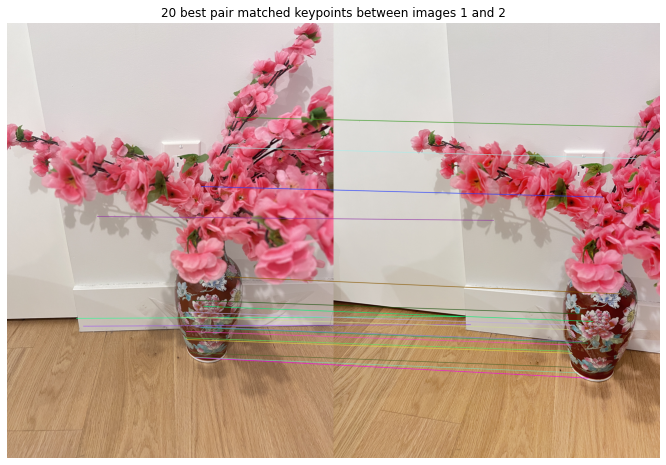

In [38]:
#2. Find matching keypoints in image 1 and image 2, and display the 20 best pairs.

bf = cv2.BFMatcher()  # cv2.NORM_HAMMING, crossCheck=True)

# Match descriptors.
matches = bf.match(descriptors[0], descriptors[1])  

# Sort them in the order of their distance.
matches_s = sorted(matches, key=lambda x: x.distance)

# Draw first 20 matches.
matched_img = cv2.drawMatches(
    img1,
    keypoints[0],
    img2,
    keypoints[1],
    matches_s[:20],
    None,
    flags=2,
    matchesThickness=3
)

plt.figure(figsize=(16, 8))
plt.imshow(matched_img)
plt.axis('off')
plt.title(
    f"20 best pair matched keypoints between images 1 and 2"
)
plt.show()

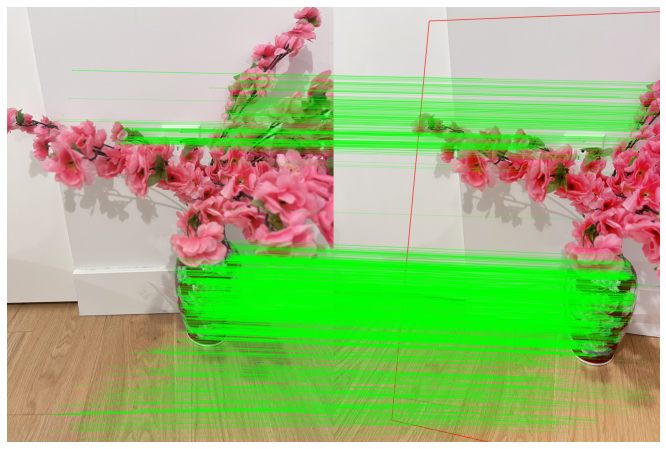

In [39]:
src_pts = np.float32([ keypoints[0][m.queryIdx].pt for m in matches ]).reshape(-1,1,2)
dst_pts = np.float32([ keypoints[1][m.trainIdx].pt for m in matches ]).reshape(-1,1,2)
M, mask = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC,5.0)
matchesMask = mask.ravel().tolist()

h,w, _ = img1.shape
pts = np.float32([ [0,0],[0,h-1],[w-1,h-1],[w-1,0] ]).reshape(-1,1,2)
dst = cv2.perspectiveTransform(pts,M)
img2_new = cv2.polylines(img2,[np.int32(dst)],True,255,3, cv2.LINE_AA)


draw_params = dict(matchColor = (0,255,0), # draw matches in green color
                   singlePointColor = None,
                   matchesMask = matchesMask, # draw only inliers
                   flags = 2)
img30 = cv2.drawMatches(img1,keypoints[0],img2_new,keypoints[1],matches,None,**draw_params)
plt.figure(figsize=(16, 8))
plt.imshow(img30)
plt.axis('off')
plt.show()

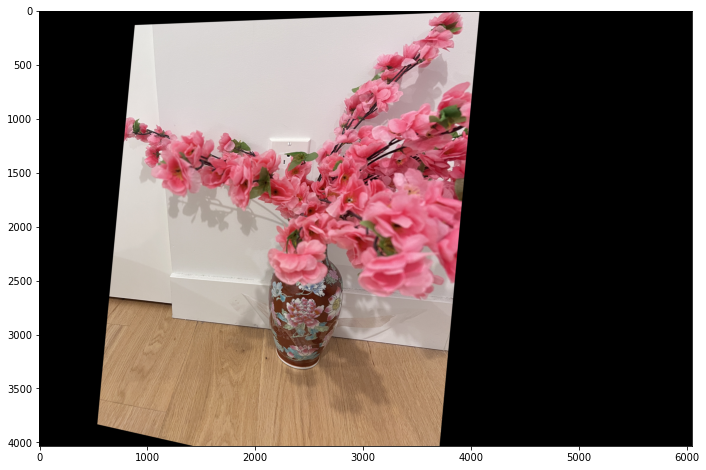

In [40]:
plt.figure(figsize=(16, 8))
warped_img1 = cv2.warpPerspective(img1, M, (img1.shape[1] + img2.shape[1], img2.shape[0]))
plt.imshow(warped_img1)

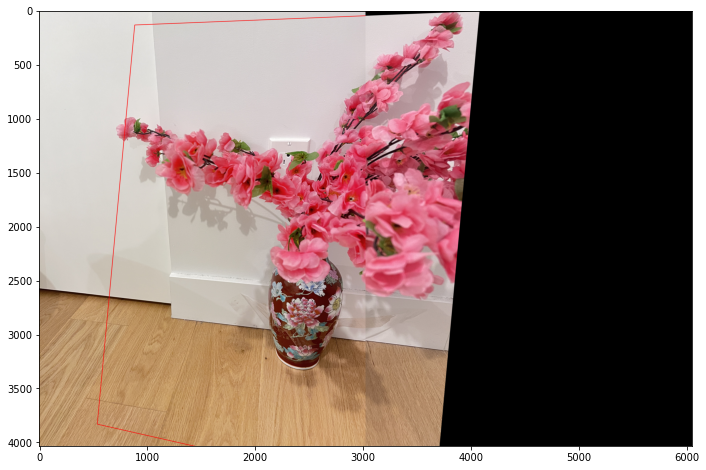

In [41]:
plt.figure(figsize=(16, 8))
warped_img1[0:img2.shape[0], 0:img2.shape[1]] = img2
plt.imshow(warped_img1)
img12 = warped_img1

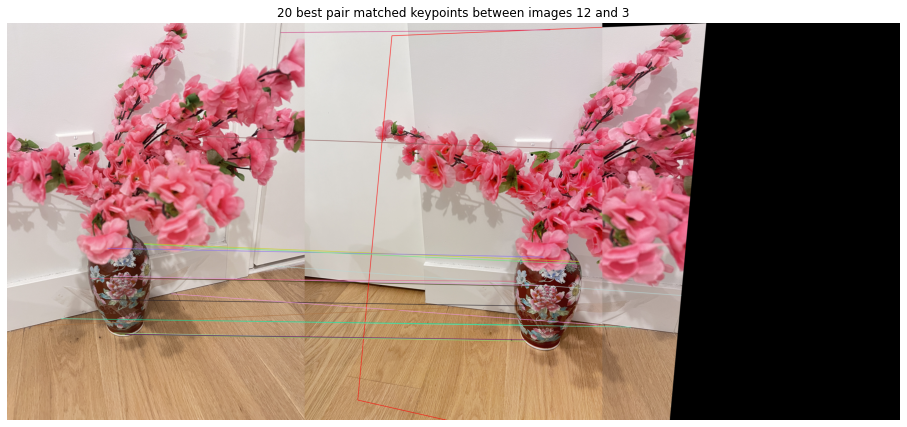

In [42]:
# 5. Compute the SIFT keypoints and corresponding descriptors for images 12 and 3.
# 6. Find matching keypoints in image 12 and image 3, and display the 20 best pairs.

img3 = cv2.imread(PATH + "Q2/image3.jpeg")  # in BGR
img3 = cv2.cvtColor(img3, cv2.COLOR_BGR2RGB)


ks, ds = sift.detectAndCompute(img3, None) # Compute the keypoints/descriptors
keypoints.append(ks)
descriptors.append(ds)

ks, ds = sift.detectAndCompute(img12, None) # Compute the keypoints/descriptors
keypoints.append(ks)
descriptors.append(ds)

bf = cv2.BFMatcher()  # cv2.NORM_HAMMING, crossCheck=True)

# Match descriptors.
matches = bf.match(descriptors[2], descriptors[3])  

# Sort them in the order of their distance.
matches_s = sorted(matches, key=lambda x: x.distance)

# Draw first 20 matches.
matched_img = cv2.drawMatches(
    img3,
    keypoints[2],
    img12,
    keypoints[3],
    matches_s[:20],
    None,
    flags=2,
    matchesThickness=3
)

plt.figure(figsize=(16, 8))
plt.imshow(matched_img)
plt.axis('off')
plt.title(
    f"20 best pair matched keypoints between images 12 and 3"
)
plt.show()

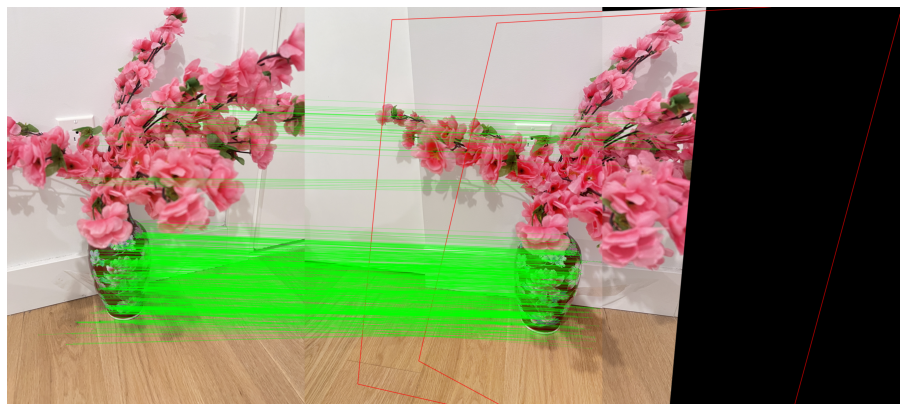

In [43]:
src_pts = np.float32([ keypoints[2][m.queryIdx].pt for m in matches ]).reshape(-1,1,2)
dst_pts = np.float32([ keypoints[3][m.trainIdx].pt for m in matches ]).reshape(-1,1,2)
M, mask = cv2.findHomography(src_pts, dst_pts, cv2.RANSAC,5.0)
matchesMask = mask.ravel().tolist()

h,w, _ = img3.shape
pts = np.float32([ [0,0],[0,h-1],[w-1,h-1],[w-1,0] ]).reshape(-1,1,2)
dst = cv2.perspectiveTransform(pts,M)
img12_new = cv2.polylines(img12,[np.int32(dst)],True,255,3, cv2.LINE_AA)


draw_params = dict(matchColor = (0,255,0), # draw matches in green color
                   singlePointColor = None,
                   matchesMask = matchesMask, # draw only inliers
                   flags = 2)
img30 = cv2.drawMatches(img3,keypoints[2],img12_new,keypoints[3],matches,None,**draw_params)
plt.figure(figsize=(16, 8))
plt.imshow(img30)
plt.axis('off')
plt.show()

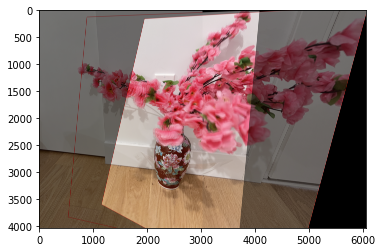

In [60]:
# plt.figure(figsize=(16, 8))
# warped_img3 = cv2.warpPerspective(img3, M, (img12.shape[1] + img3.shape[1], img3.shape[0]))
# plt.imshow(warped_img3)
# results = warped_img3

img2_transformed = cv2.warpPerspective(img3, M, (img12.shape[1], img12.shape[0]))
result = cv2.addWeighted(img12, 0.5, img2_transformed, 0.5, 0)
plt.imshow(result)

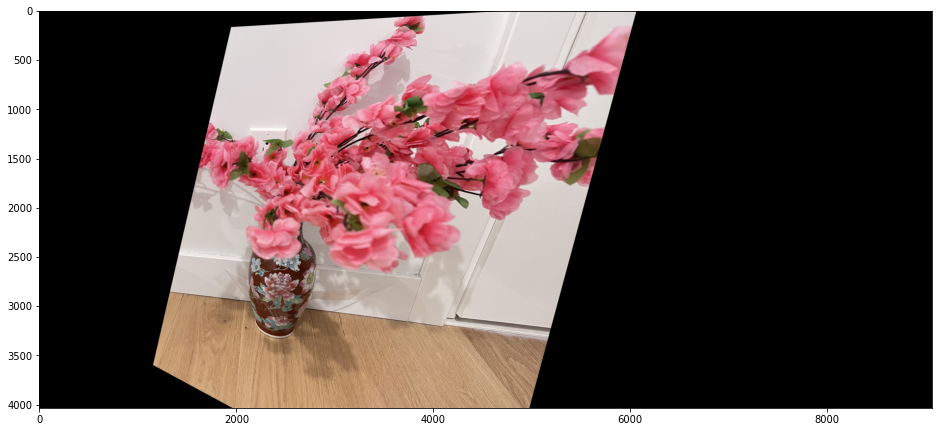

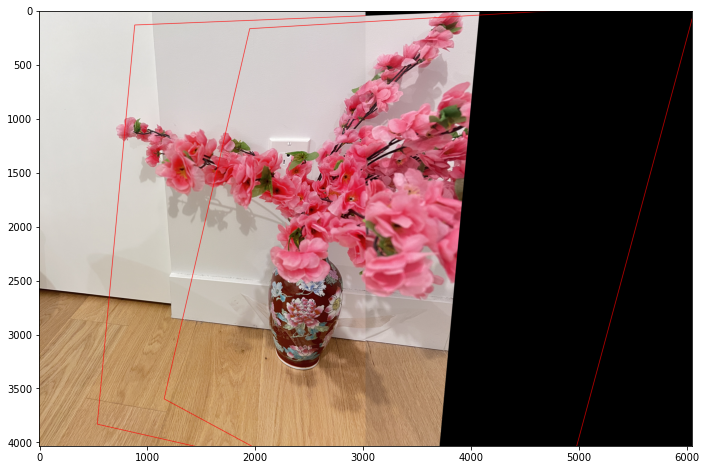

In [56]:
plt.figure(figsize=(16, 8))
plt.imshow(warped_img3)
plt.figure(figsize=(16, 8))
plt.imshow(img12)

In [52]:
print(img12.shape)
print(warped_img3.shape)

# plt.figure(figsize=(16, 8))
# warped_img3[0:img12.shape[0], 0:img12.shape[1]] = img12
# plt.imshow(warped_img3)
# results = img12

(4032, 6048, 3)
(4032, 9072, 3)


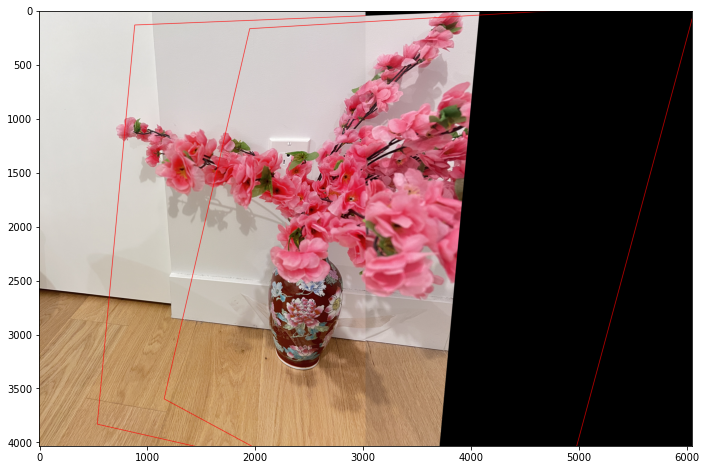

In [62]:
result = warped_img3[0:img12.shape[0], 0:img12.shape[1]] = img12
plt.figure(figsize=(16, 8))
plt.imshow(result)

(4032, 6048, 3)
(4032, 6048, 3)


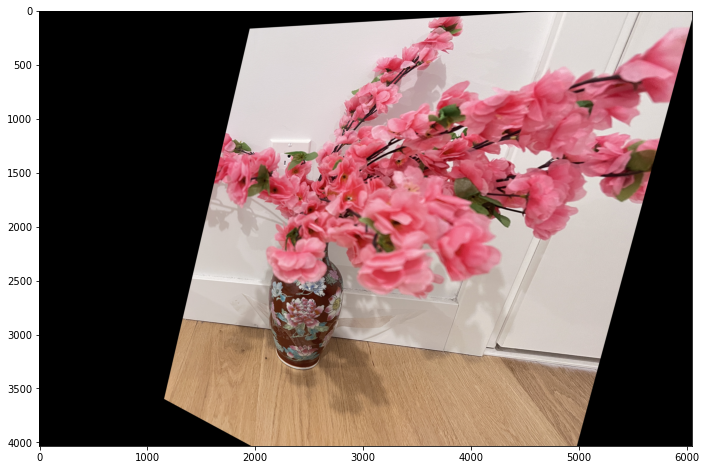

In [26]:
def linear_blending(src1, src2, alpha=0.5):
    print(src1.shape)
    print(src2.shape)
    
    beta = (1.0 - alpha)
    dst = cv2.addWeighted(src1, alpha, src2, beta, 0.0)
    return dst

plt.figure(figsize=(16, 8))
plt.imshow(linear_blending(warped_img3, img12))

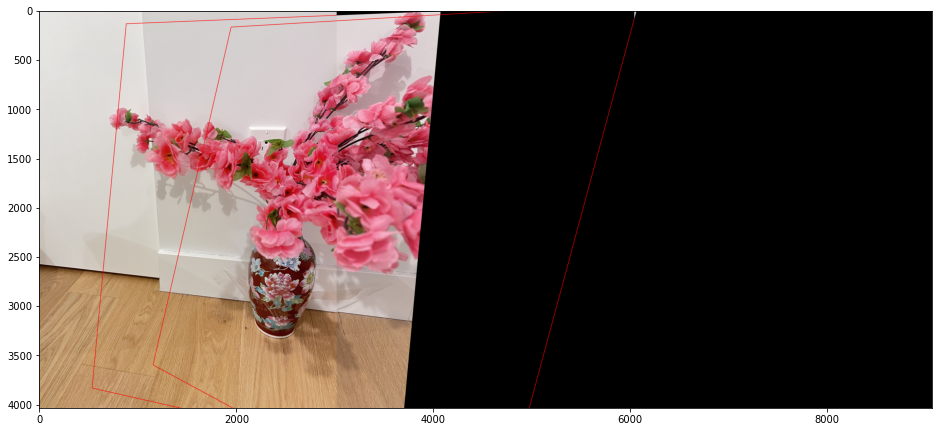

In [88]:
# result[0:img12.shape[0], 0:img12.shape[1]] = img12
# plt.figure(figsize=(16, 8))
# plt.imshow(result)

plt.figure(figsize=(16, 8))
warped_img3[0:img12.shape[0], 0:img12.shape[1]] = img12
plt.imshow(warped_img3)
# img12 = warped_img1

## 3. Face detection

In [76]:
TRAIN_PATH = PATH + "Q3/faces"
training_list = os.listdir(TRAIN_PATH) 

dataset = []

for img in training_list:
    image_path = os.path.join(TRAIN_PATH, img)
    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    dataset.append(image)

# Convert the list of images to a numpy array
dataset = np.array(dataset)

# Print the shape of the images array
print("Dataset shape:", dataset.shape)

Dataset shape: (400, 218, 178)


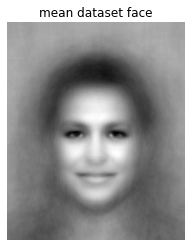

In [84]:
#1. Display the mean face of the training dataset.

mean_face = np.mean(dataset, axis=0)
plt.imshow(mean_face, cmap = 'gray')
plt.title("mean dataset face")
plt.axis(False)
plt.show()

In [85]:
# Then, we subtract the mean face from each face in the dataset
centered_faces = dataset - mean_face

# Next, we calculate the covariance matrix of the centered faces
covariance_matrix = np.cov(centered_faces, rowvar=False)

# Finally, we calculate the eigenvectors and eigenvalues of the covariance matrix
eigenvalues, eigenvectors = np.linalg.eig(covariance_matrix)

# Sort the eigenvalues and eigenvectors in descending order
sorted_indices = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[sorted_indices]
eigenvectors = eigenvectors[:, sorted_indices]


ValueError: m has more than 2 dimensions